> **Portfolio summary:** Extracting totals from receipt images with the Gemini vision model and scoring them against ground truth.
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

## Reflection on Receipt Data Extraction using Gemini VLM

This notebook demonstrates a practical application of the Gemini Vision Language Model (VLM) for extracting structured information from unstructured receipt images. The primary objective was to extract the total purchase price from a dataset of receipt images (`CORD-v2`) and evaluate the VLM's performance against ground truth data.

The process involved loading the dataset, preprocessing ground truth JSON to extract actual total prices, and then using the Gemini 2.5 Flash model to predict the total price for a sample of receipts. A notable challenge encountered during this phase was frequent API quota limits, which required implementing a retry mechanism with exponential backoff to handle rate limiting gracefully, though some errors persisted. Finally, the predicted prices were compared against the ground truth to calculate evaluation metrics such as Mean Absolute Error (MAE) and accuracy within 5% and 10% thresholds, providing insights into the model's effectiveness for this specific task.
```

In [ ]:
from google.colab import userdata
import os

# Load the API key from Colab secrets, assuming it's stored as 'GEMINI_API_KEY'
GOOGLE_API_KEY = userdata.get('GEMINI_API_KEY')

# Set the environment variable for the Gemini API
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

print("API key loaded and environment variable set.")

API key loaded and environment variable set.

In [ ]:
import google.generativeai as genai

print("Listing available Gemini models:")
for m in genai.list_models():
    if "generateContent" in m.supported_generation_methods:
        print(f"Name: {m.name}, Description: {m.description}")

Listing available Gemini models:
Name: models/gemini-2.5-flash, Description: Stable version of Gemini 2.5 Flash, our mid-size multimodal model that supports up to 1 million tokens, released in June of 2025.
Name: models/gemini-2.5-pro, Description: Stable release (June 17th, 2025) of Gemini 2.5 Pro
Name: models/gemini-2.0-flash, Description: Gemini 2.0 Flash
Name: models/gemini-2.0-flash-001, Description: Stable version of Gemini 2.0 Flash, our fast and versatile multimodal model for scaling across diverse tasks, released in January of 2025.
Name: models/gemini-2.0-flash-lite-001, Description: Stable version of Gemini 2.0 Flash-Lite
Name: models/gemini-2.0-flash-lite, Description: Gemini 2.0 Flash-Lite
Name: models/gemini-2.5-flash-preview-tts, Description: Gemini 2.5 Flash Preview TTS
Name: models/gemini-2.5-pro-preview-tts, Description: Gemini 2.5 Pro Preview TTS
Name: models/gemma-3-1b-it, Description: 
Name: models/gemma-3-4b-it, Description: 
Name: models/gemma-3-12b-it, Descripti

In [ ]:
# Initialize the Gemini Pro Vision model with the updated name
gemini_pro_vision = genai.GenerativeModel('gemini-2.5-flash')

print("Google Gemini 2.5 Flash model initialized.")

Google Gemini 2.5 Flash model initialized.

In [ ]:
from datasets import load_dataset

ds = load_dataset("naver-clova-ix/cord-v2")

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
    test: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
})

In [ ]:
import pandas as pd
pd.DataFrame(ds['train'][:5])

,image,ground_truth
0,<PIL.PngImagePlugin.PngImageFile image mode=RG...,"{""gt_parse"": {""menu"": [{""nm"": ""Nasi Campur Bal..."
1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,"{""gt_parse"": {""menu"": [{""nm"": ""SPGTHY BOLOGNAS..."
2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,"{""gt_parse"": {""menu"": [{""nm"": ""HAKAU UDANG"", ""..."
3,<PIL.PngImagePlugin.PngImageFile image mode=RG...,"{""gt_parse"": {""menu"": [{""nm"": ""Bintang Bremer""..."
4,<PIL.PngImagePlugin.PngImageFile image mode=RG...,"{""gt_parse"": {""menu"": {""nm"": ""BASO BIHUN"", ""un..."


Displaying the first 5 images and their ground truth in a table:


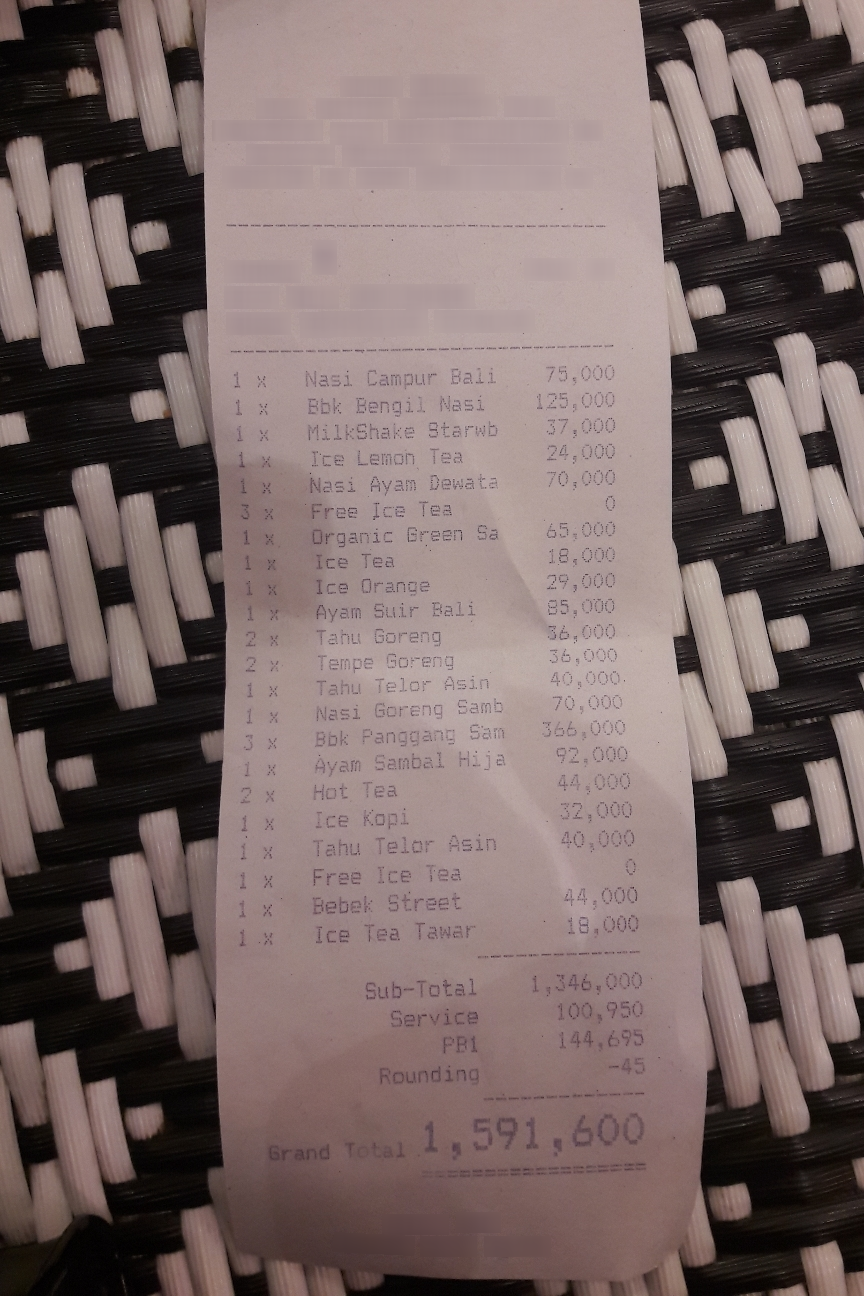
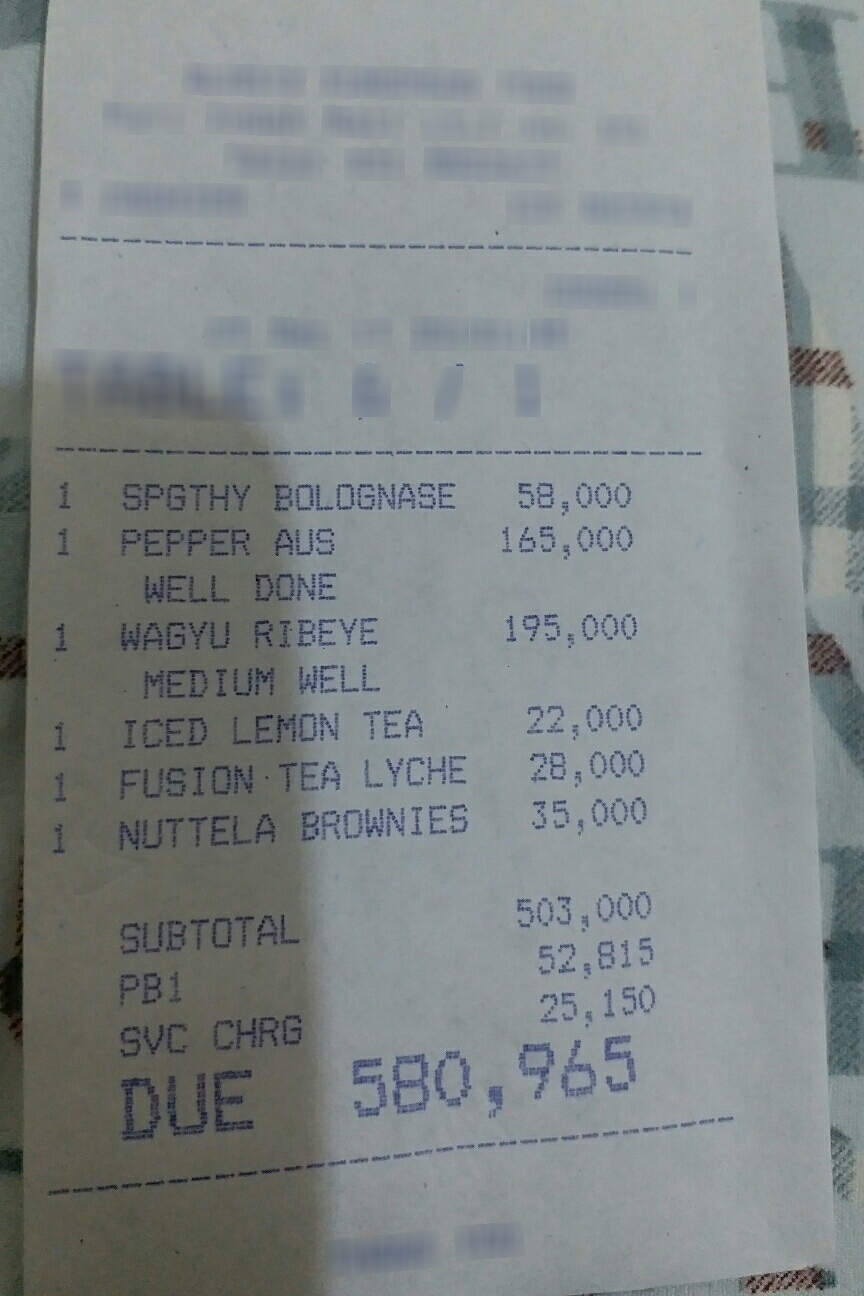
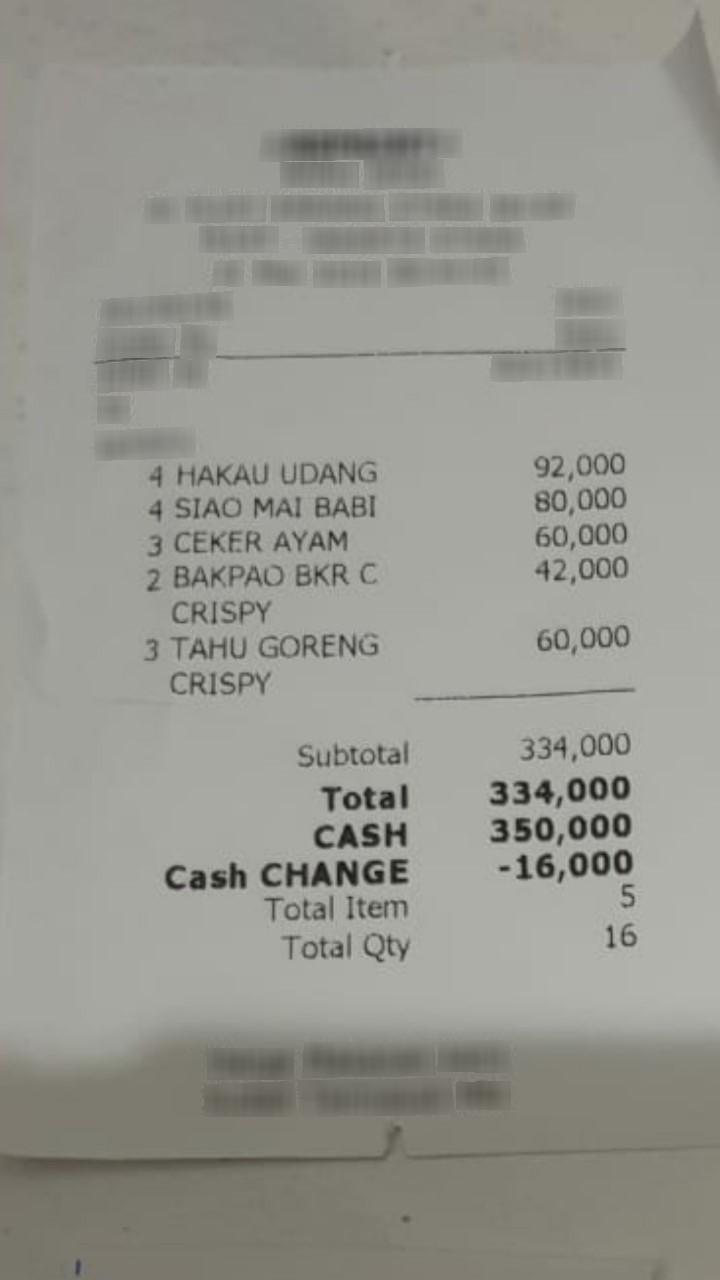
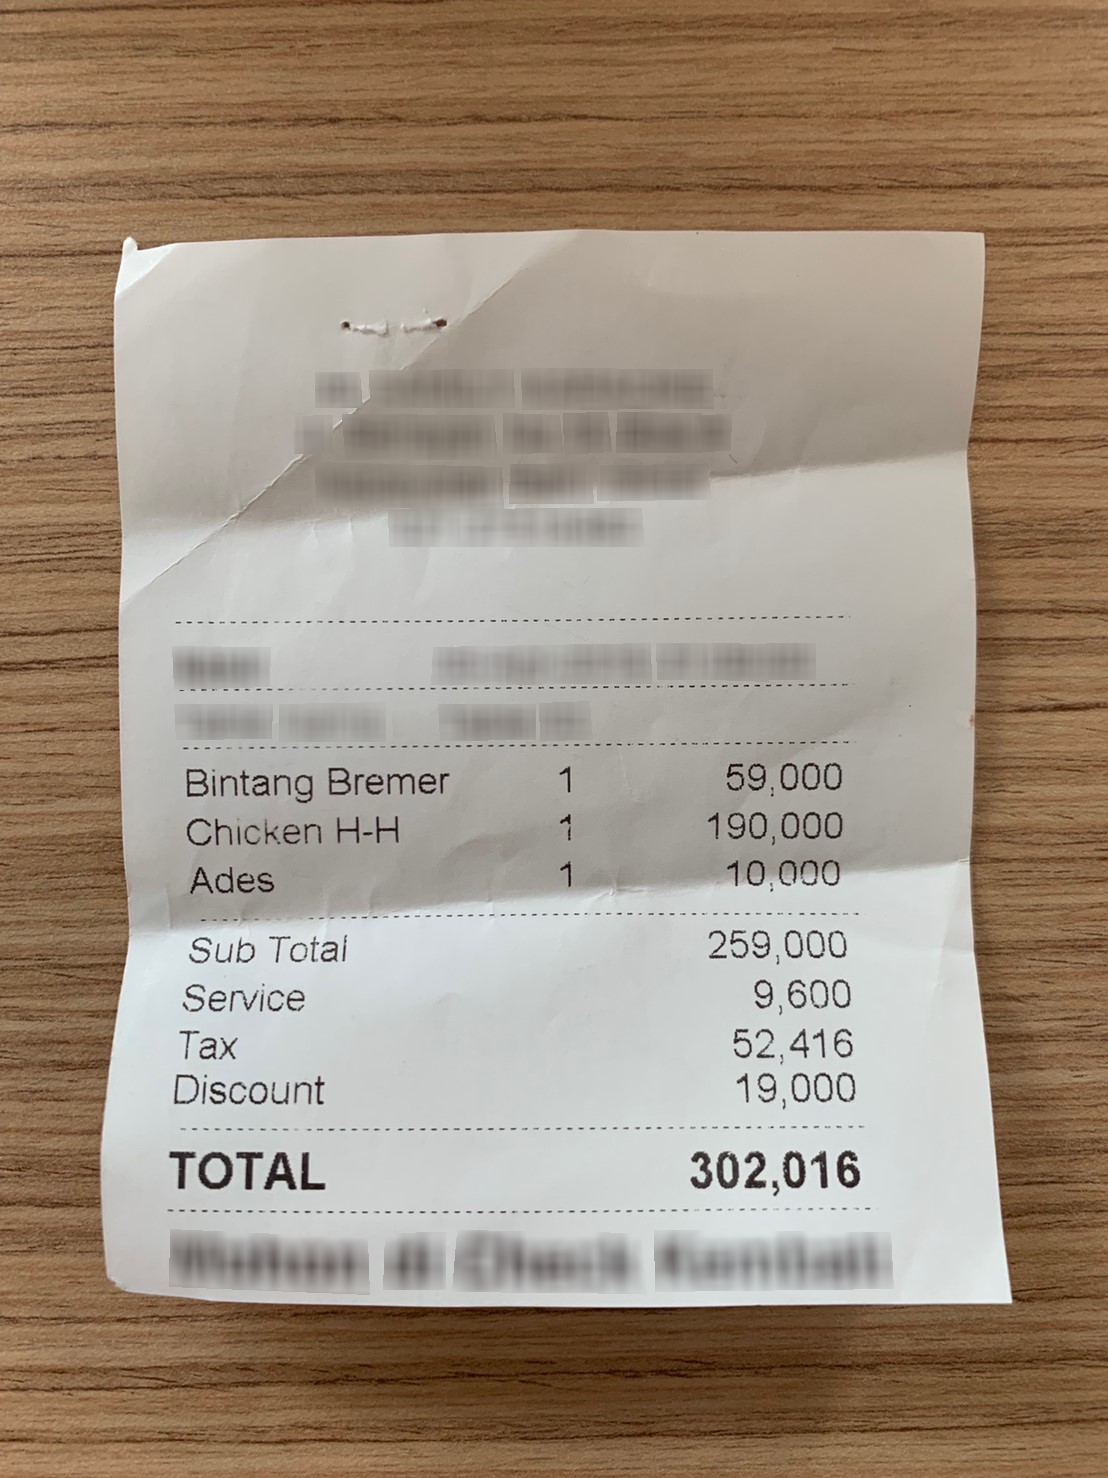
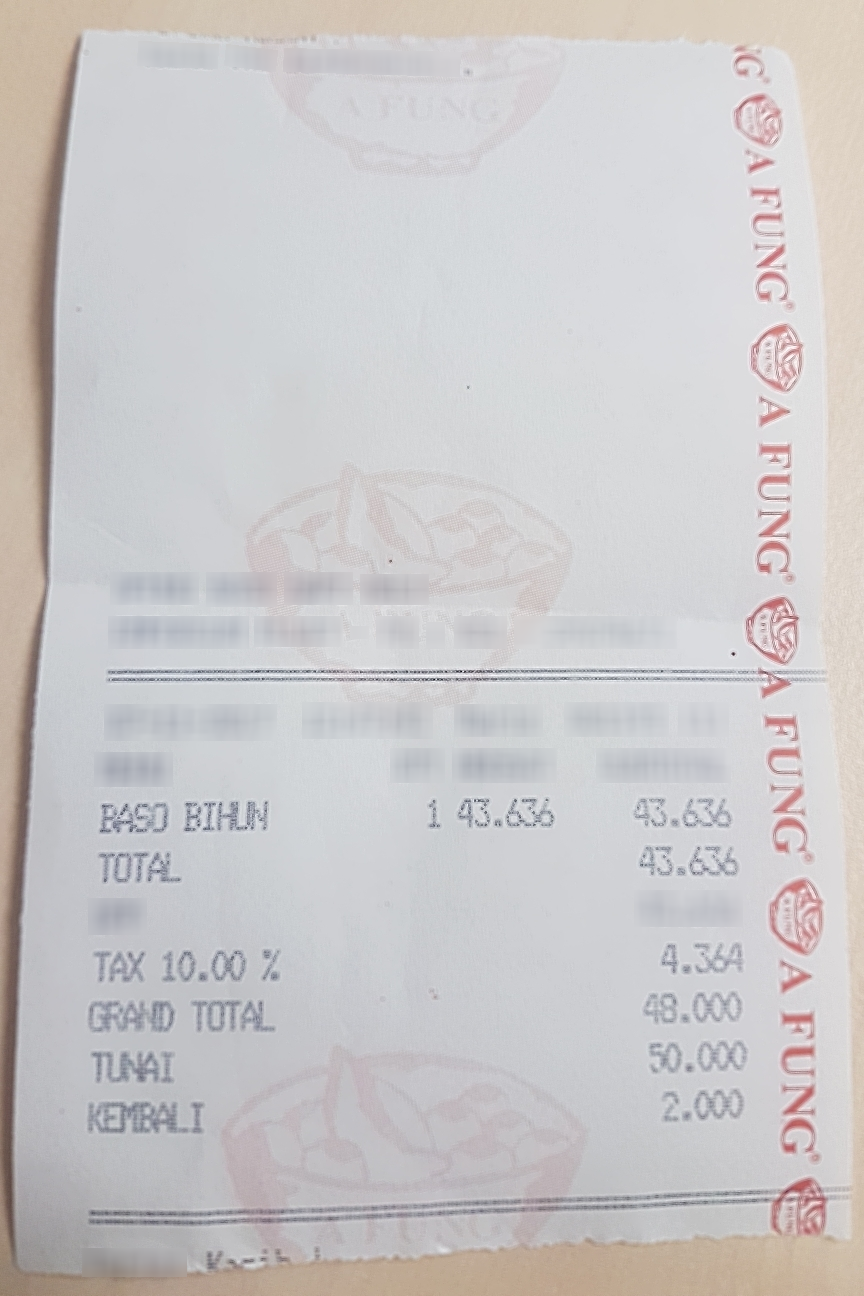

In [ ]:
from IPython.display import display, HTML
import pandas as pd
import json
import io
import base64

# Assuming the DataFrame with the first 5 rows is named 'df_first_5'
# from the previous execution of cell NypN9z20Mm4E.
# If not, let's re-create it here for clarity:
df_first_5 = pd.DataFrame(ds['train'][:5])

print("Displaying the first 5 images and their ground truth in a table:")

html_output = """
<style>
  table {
    border-collapse: collapse;
    width: 100%;
  }
  th, td {
    border: 1px solid #ddd;
    padding: 8px;
    text-align: left;
    vertical-align: top;
  }
  th {
    background-color: #f2f2f2;
  }
  img {
    max-width: 300px; /* Limit image width */
    height: auto;
    display: block; /* Remove extra space below image */
  }
  pre {
    white-space: pre-wrap; /* Preserve whitespace and wrap text */
    word-wrap: break-word;
  }
</style>
<table>
  <tr>
    <th>Image</th>
    <th>Ground Truth</th>
  </tr>
"""

for i, row in df_first_5.iterrows():
    html_output += "<tr>"
    # Image column
    img_bytes = io.BytesIO()
    row['image'].save(img_bytes, format='PNG') # Save the PIL image to bytes
    img_base64 = base64.b64encode(img_bytes.getvalue()).decode('utf-8')
    html_output += f"<td><img src='data:image/png;base64,{img_base64}' width='200'></td>"

    # Ground Truth column
    ground_truth_json = json.loads(row['ground_truth'])
    html_output += f"<td><pre>{json.dumps(ground_truth_json, indent=2)}</pre></td>"
    html_output += "</tr>"
html_output += "</table>"

display(HTML(html_output))

This code block defines the process of extracting the image, store name, and overall total price for each receipt in `ds['train']`. It cleans the total price string to ensure it can be converted to a float and then creates a DataFrame named `df_receipt_summary` with the extracted information.

In [ ]:
import pandas as pd
import json
import re # Import regular expression module

# Initialize an empty list to store the extracted data for each receipt
receipt_data_df = []

# Iterate through each record in ds['train']
for record in ds['train']:
    image = record['image']
    ground_truth_str = record['ground_truth']

    store_name = None
    total_price = None

    try:
        ground_truth_json = json.loads(ground_truth_str)
        gt_parse = ground_truth_json.get('gt_parse', {})

        # 5. Extract the store_name
        company_name = gt_parse.get('company', {}).get('name')
        seller_name = gt_parse.get('seller', {}).get('name')

        if company_name:
            store_name = company_name
        elif seller_name:
            store_name = seller_name

        # 6. Extract the total_price string
        total_info = gt_parse.get('total', {})
        total_price_str = total_info.get('total_price')

        # 7. Clean and convert total_price to float
        if total_price_str is not None and isinstance(total_price_str, str):
            # Remove any non-digit, non-decimal characters (e.g., currency symbols, spaces, thousands separators)
            # First, handle comma as decimal if present, convert to dot, then remove other non-digits except first dot
            cleaned_price = total_price_str.replace(',', '.')

            # If there are multiple dots (e.g., "1.234.567.89"), assume all but the last are thousands separators
            # and consolidate them into a single decimal point or remove.
            # A more robust way: keep digits and only one decimal point.
            parts = re.findall(r'\d+', cleaned_price) # Extract all number sequences
            if parts:
                numeric_string = ''.join(parts)
                # Find the last potential decimal separator
                last_dot_index = cleaned_price.rfind('.')
                if last_dot_index != -1 and last_dot_index > cleaned_price.rfind(parts[-1]): # Check if it's actually a decimal after the last number
                    # Reconstruct with the decimal point
                    integer_part = ''.join(re.findall(r'\d', cleaned_price[:last_dot_index]))
                    decimal_part = ''.join(re.findall(r'\d', cleaned_price[last_dot_index+1:]))
                    cleaned_price = f"{integer_part}.{decimal_part}"
                else:
                    cleaned_price = numeric_string
            else:
                cleaned_price = ""

            try:
                if cleaned_price:
                    total_price = float(cleaned_price)
                else:
                    total_price = None
            except ValueError:
                total_price = None # Conversion failed

        # 8. Append extracted data to the list
        receipt_data_df.append({
            'image': image,
            'store_name': store_name,
            'total_price': total_price
        })

    except json.JSONDecodeError as e:
        print(f"Error decoding JSON for a record: {e}")
        continue # Skip to the next record if JSON is invalid
    except Exception as e:
        print(f"An unexpected error occurred for a record: {e}")
        continue # Skip to the next record if an error occurs

# Create the new DataFrame
df_receipt_summary = pd.DataFrame(receipt_data_df)

print(f"Created df_receipt_summary with {len(df_receipt_summary)} records.")
print("First 5 rows of df_receipt_summary:")
display(df_receipt_summary.head())

Created df_receipt_summary with 800 records.
First 5 rows of df_receipt_summary:

,image,store_name,total_price
0,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,1591600.0
1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,580965.0
2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,334000.0
3,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,302016.0
4,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,48000.0


In [ ]:
df_receipt = df_receipt_summary

print(f"Number of records in df_receipt: {len(df_receipt)}")
print("First 5 rows of df_receipt:")
display(df_receipt.head())

Number of records in df_receipt: 800
First 5 rows of df_receipt:

,image,store_name,total_price
0,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,1591600.0
1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,580965.0
2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,334000.0
3,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,302016.0
4,<PIL.PngImagePlugin.PngImageFile image mode=RG...,None,48000.0


In [ ]:
num_none_store_name = df_receipt['store_name'].isnull().sum()
print(f"Number of records with None in 'store_name': {num_none_store_name}")

Number of records with None in 'store_name': 800

This cell removes the 'store_name' column from the `df_receipt` DataFrame, as it was found to be entirely `None`. It then displays the head of the DataFrame to confirm the column's removal.

In [ ]:
df_receipt = df_receipt.drop(columns=['store_name'])
print(" 'store_name' column removed from df_receipt.")
print("First 5 rows of df_receipt after column removal:")
display(df_receipt.head())

 'store_name' column removed from df_receipt.
First 5 rows of df_receipt after column removal:

,image,total_price
0,<PIL.PngImagePlugin.PngImageFile image mode=RG...,1591600.0
1,<PIL.PngImagePlugin.PngImageFile image mode=RG...,580965.0
2,<PIL.PngImagePlugin.PngImageFile image mode=RG...,334000.0
3,<PIL.PngImagePlugin.PngImageFile image mode=RG...,302016.0
4,<PIL.PngImagePlugin.PngImageFile image mode=RG...,48000.0


In [ ]:
df_test_receipts = df_receipt.sample(n=15, random_state=42).copy()

print(f"Number of records in df_test_receipts: {len(df_test_receipts)}")
print("First 5 rows of df_test_receipts:")
display(df_test_receipts.head())

Number of records in df_test_receipts: 15
First 5 rows of df_test_receipts:

,image,total_price
696,<PIL.PngImagePlugin.PngImageFile image mode=RG...,52500.0
667,<PIL.PngImagePlugin.PngImageFile image mode=RG...,105999.0
63,<PIL.PngImagePlugin.PngImageFile image mode=RG...,23600.0
533,<PIL.PngImagePlugin.PngImageFile image mode=RG...,60000.0
66,<PIL.PngImagePlugin.PngImageFile image mode=RG...,57900.0


In [ ]:
prompt_total_price = "Extract the total amount from this receipt. Provide only the numerical value as a float."

print(f"Prompt for total price extraction defined: {prompt_total_price}")

Prompt for total price extraction defined: Extract the total amount from this receipt. Provide only the numerical value as a float.

## Process `df_test_receipts` with Gemini


Iterate through each row in `df_test_receipts`, call the Gemini VLM with the defined prompt, parse its response to extract the predicted `total_price`, and add it as a new column, `predicted_total_price`, to `df_test_receipts`. Handle potential errors by assigning `None` or `NaN`.

### Instructions:
1. Initialize an empty list, `predicted_prices`, to store the VLM's responses.
2. Iterate through each `image` in the `df_test_receipts` DataFrame.
3. For each image, prepare the content for the VLM by converting the PIL image to JPEG bytes and combining it with the `prompt_total_price`.
4. Call `gemini_pro_vision.generate_content()` with the prepared content.
5. Attempt to extract the numerical `total_price` from the VLM's response.
   - If the response contains a valid float, convert it.
   - If extraction fails (e.g., due to an invalid response format, non-numeric output, or API error), append `None` to `predicted_prices`.
6. After iterating through all images, add the `predicted_prices` list as a new column named `predicted_total_price` to `df_test_receipts`.
7. Print the first few rows of `df_test_receipts` to show the newly added `predicted_total_price` column.

In [ ]:
import io
from PIL import Image
import numpy as np # For NaN values
import time # Import time for sleep

predicted_prices = []

print("Processing receipts with Gemini VLM...")

for index, row in df_test_receipts.iterrows():
    image = row['image']
    predicted_price = None
    retries = 0
    max_retries = 5
    base_delay = 5 # seconds

    while retries < max_retries:
        try:
            # Convert PIL Image to JPEG bytes
            img_byte_arr = io.BytesIO()
            image.save(img_byte_arr, format='JPEG')
            img_byte_arr = img_byte_arr.getvalue()

            # Create content list for Gemini
            contents = [prompt_total_price, {"mime_type": "image/jpeg", "data": img_byte_arr}]

            # Call Gemini VLM
            response = gemini_pro_vision.generate_content(contents)
            response_text = response.text.strip()

            # Attempt to convert response to float
            predicted_price = float(response_text)
            break # Exit retry loop if successful

        except ValueError:
            # Handle cases where the response is not a valid float
            print(f"Warning: Could not convert '{response_text}' to float for index {index}. Setting to NaN.")
            predicted_price = np.nan
            break # No point in retrying if response format is invalid
        except Exception as e:
            if "429 Quota exceeded" in str(e) and retries < max_retries - 1:
                delay = base_delay * (2 ** retries) # Exponential backoff
                print(f"Quota exceeded for index {index}. Retrying in {delay} seconds (attempt {retries + 1}/{max_retries})...")
                time.sleep(delay)
                retries += 1
            else:
                # Handle other potential errors (e.g., API errors, image processing errors)
                print(f"Error processing receipt at index {index}: {e}. Setting to NaN.")
                predicted_price = np.nan
                break # Exit retry loop if other error or max retries reached

    predicted_prices.append(predicted_price)

# Add the predicted prices as a new column to df_test_receipts
df_test_receipts['predicted_total_price'] = predicted_prices

print("Receipt processing complete.")
print("First 5 rows of df_test_receipts with predicted_total_price:")
display(df_test_receipts.head())

Processing receipts with Gemini VLM...
Error processing receipt at index 346: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-2.5-flash
Please retry in 35.761948348s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerMinutePerProjectPerModel-FreeTier"
  quota_dimensions {
    key: "model"
    value: "gemini-2.5-flash"
  }
  quota_dimensions {
    key: "location"
    value: "global"
  }
  quota_value: 5
}
, retry_delay {
  seconds: 35
}
]. Setting to NaN.
Error process

,image,total_price,predicted_total_price
696,<PIL.PngImagePlugin.PngImageFile image mode=RG...,52500.0,52500.0
667,<PIL.PngImagePlugin.PngImageFile image mode=RG...,105999.0,105999.0
63,<PIL.PngImagePlugin.PngImageFile image mode=RG...,23600.0,23600.0
533,<PIL.PngImagePlugin.PngImageFile image mode=RG...,60000.0,60000.0
66,<PIL.PngImagePlugin.PngImageFile image mode=RG...,57900.0,57.9


## Evaluate Predictions

### Subtask:
Compare the `predicted_total_price` with the `total_price` (ground truth) in `df_test_receipts` and calculate appropriate evaluation metrics: Mean Absolute Error (MAE), number of successful extractions, and accuracy within 5% and 10% thresholds. Then, display the results.

In [ ]:
import numpy as np

# 1. Filter df_test_receipts to include only successfully extracted predictions
df_evaluated_predictions = df_test_receipts.dropna(subset=['predicted_total_price']).copy()

# 3. Count the number of successful extractions
num_successful_extractions = len(df_evaluated_predictions)

if num_successful_extractions > 0:
    # Calculate absolute differences
    df_evaluated_predictions['absolute_difference'] = abs(df_evaluated_predictions['total_price'] - df_evaluated_predictions['predicted_total_price'])

    # 2. Calculate Mean Absolute Error (MAE)
    mae = df_evaluated_predictions['absolute_difference'].mean()

    # Calculate percentage differences
    df_evaluated_predictions['percentage_difference'] = (df_evaluated_predictions['absolute_difference'] / df_evaluated_predictions['total_price']) * 100

    # 4. Calculate accuracy within a 5% threshold
    accuracy_5_percent = (df_evaluated_predictions['percentage_difference'] <= 5).mean() * 100

    # 5. Calculate accuracy within a 10% threshold
    accuracy_10_percent = (df_evaluated_predictions['percentage_difference'] <= 10).mean() * 100

    print("\n--- Evaluation Metrics ---")
    print(f"Number of successful extractions: {num_successful_extractions}")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Accuracy within 5% threshold: {accuracy_5_percent:.2f}%")
    print(f"Accuracy within 10% threshold: {accuracy_10_percent:.2f}%")
    print("--------------------------")

else:
    print("\nNo successful extractions to evaluate.")

# 7. Display df_test_receipts with total_price and predicted_total_price columns
print("\nSample of df_test_receipts with actual and predicted total prices:")
display(df_test_receipts[['total_price', 'predicted_total_price']].head(15))



--- Evaluation Metrics ---
Number of successful extractions: 6
Mean Absolute Error (MAE): 9640.35
Accuracy within 5% threshold: 83.33%
Accuracy within 10% threshold: 83.33%
--------------------------

Sample of df_test_receipts with actual and predicted total prices:

,total_price,predicted_total_price
696,52500.0,52500.0
667,105999.0,105999.0
63,23600.0,23600.0
533,60000.0,60000.0
66,57900.0,57.9
621,80000.0,80000.0
346,45000.0,NaN
490,NaN,NaN
760,28000.0,NaN
456,159638.0,NaN


In [ ]:
import numpy as np

# 1. Identify rows where predicted_total_price is not null or NaN
df_eval = df_test_receipts.dropna(subset=['predicted_total_price']).copy()

# 3. Count the number of non-null entries
num_success = len(df_eval)

if num_success > 0:
    # 2. Calculate Mean Absolute Error (MAE)
    df_eval['abs_error'] = abs(df_eval['total_price'] - df_eval['predicted_total_price'])
    mae = df_eval['abs_error'].mean()

    # Calculate percentage error
    # Avoid division by zero if total_price is 0
    df_eval['pct_error'] = df_eval['abs_error'] / df_eval['total_price']

    # 4. Calculate percentage within 5% threshold
    accuracy_5pct = (df_eval['pct_error'] <= 0.05).mean() * 100

    # 5. Calculate percentage within 10% threshold
    accuracy_10pct = (df_eval['pct_error'] <= 0.10).mean() * 100

    # 6. Print statements to display the results
    print(f"--- Evaluation Metrics ---")
    print(f"Total Successful Extractions: {num_success}")
    print(f"Mean Absolute Error (MAE): {mae:.2f}")
    print(f"Accuracy within 5% threshold: {accuracy_5pct:.2f}%")
    print(f"Accuracy within 10% threshold: {accuracy_10pct:.2f}%")
else:
    print("No successful extractions found to calculate metrics.")

--- Evaluation Metrics ---
Total Successful Extractions: 6
Mean Absolute Error (MAE): 9640.35
Accuracy within 5% threshold: 83.33%
Accuracy within 10% threshold: 83.33%